In [1]:
import datetime

from rocketpy import Environment, Flight, Function, Rocket
from rocketpy import SolidMotor

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

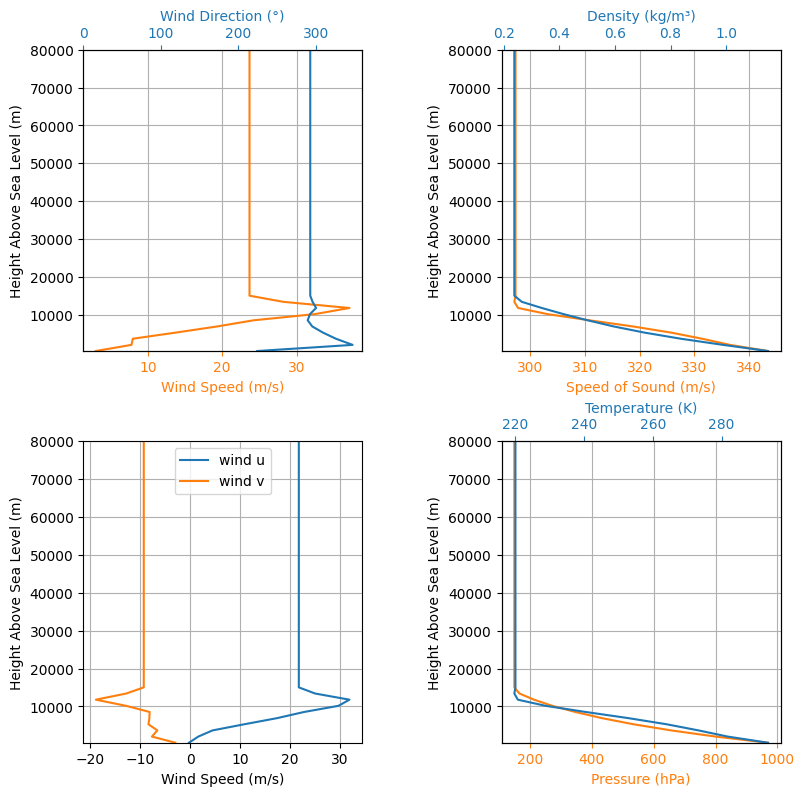


Gravity Details

Acceleration of gravity at surface level:    9.8028 m/s²
Acceleration of gravity at  14.035 km (ASL): 9.7610 m/s²


Launch Site Details

Launch Date: 2026-07-11 14:00:00 UTC
Launch Site Latitude: 42.70446°
Launch Site Longitude: -77.19169°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 320501.59 W    4730325.42 N
Launch Site UTM zone: 17T
Launch Site Surface Elevation: 421.7 m


Atmospheric Model Details

Atmospheric Model Type: Windy
Windy Maximum Height: 14.035 km

Surface Atmospheric Conditions

Surface Wind Speed: 3.01 m/s
Surface Wind Direction: 224.52°
Surface Wind Heading: 183.41°
Surface Pressure: 969.29 hPa
Surface Temperature: 293.49 K
Surface Air Density: 1.150 kg/m³
Surface Speed of Sound: 343.43 m/s


Earth Model Details

Earth Radius at Launch site: 6368.35 km
Semi-major Axis: 6378.14 km
Semi-minor Axis: 6356.75 km
Flattening: 0.0034


Atmospheric Model Plots



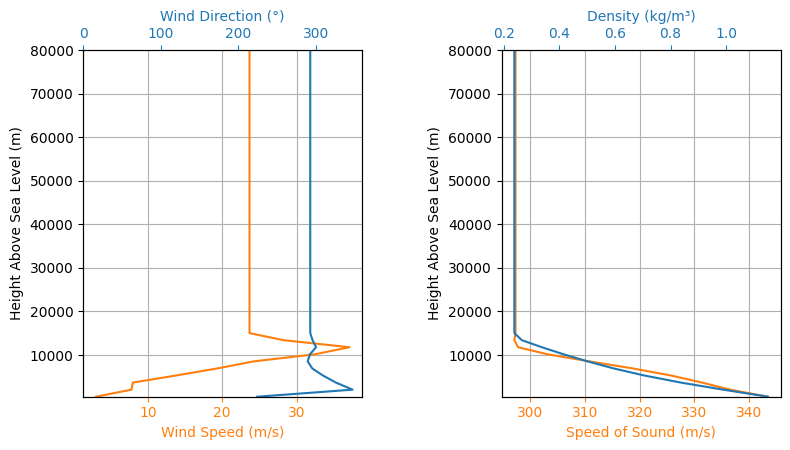

In [2]:
env_windy = Environment(
    date=(2026, 7, 11, 14),
    latitude=42.70446,
    longitude=-77.19169,
    elevation = 421.7
)


env_windy.set_atmospheric_model(type="Windy", file="ECMWF")
env_windy_ecmwf = env_windy
env_windy_ecmwf.plots.atmospheric_model()

env_windy.elevation = 421.7
env_windy.info()

In [3]:
print("Environment elevation:", env_windy.elevation)

Environment elevation: 421.7


Nozzle Details
Nozzle Radius: 0.012446 m
Nozzle Throat Radius: 0.00622040816 m

Grain Details
Number of Grains: 3
Grain Spacing: 0.0015875 m
Grain Density: 1880 kg/m3
Grain Outer Radius: 0.0166116 m
Grain Inner Radius: 0.0077343 m
Grain Height: 0.046101 m
Grain Volume: 0.000 m3
Grain Mass: 0.059 kg

Motor Details
Total Burning Time: 0.57 s
Total Propellant Mass: 0.177 kg
Structural Mass Ratio: 0.442
Average Propellant Exhaust Velocity: 1774.687 m/s
Average Thrust: 549.659 N
Maximum Thrust: 643.372 N at 0.157 s after ignition.
Total Impulse: 313.305 Ns



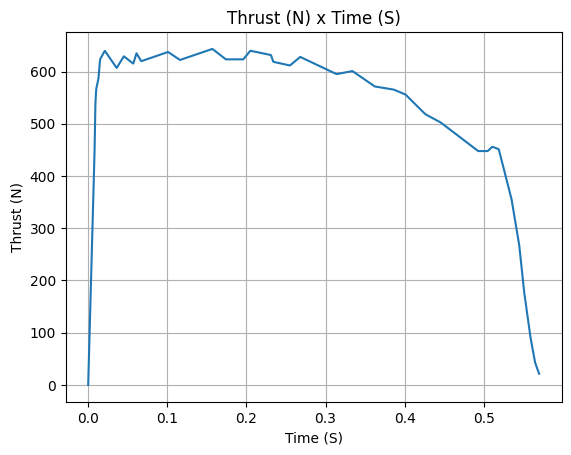

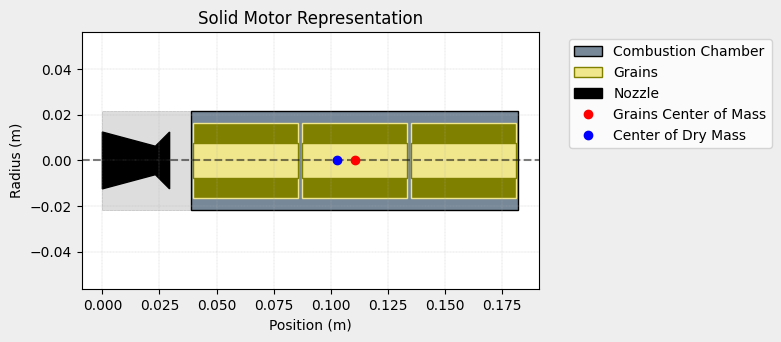

In [4]:
h550 = SolidMotor(
  thrust_source="Rocketpy Files/AeroTech_HP-H550ST.eng",
  dry_mass=0.140,
  dry_inertia = (0.00260, 0.00260, 0.000111),
  nozzle_radius=0.012446,
  grain_number=3,
  grain_density=1880,
  grain_outer_radius=0.0332232/2,
  grain_initial_inner_radius=0.0154686/2,
  grain_initial_height=0.046101,
  grain_separation=0.0015875 ,
  grains_center_of_mass_position=0.11049,
  center_of_dry_mass_position=0.10287,
  nozzle_position=0 ,
  burn_time=0.57,
  throat_radius=0.00622040816 ,
  coordinate_system_orientation="nozzle_to_combustion_chamber",
)

h550.info()
h550.draw()

In [5]:
Phoenix = Rocket(
    radius=0.0508,
    mass=1.497,
    inertia=(0.193465243, 0.193515502, 0.000334175),
    power_off_drag="Rocketpy Files/paul_data_sorted.csv",
    power_on_drag="Rocketpy Files/paul_data_sorted.csv",
    center_of_mass_without_motor=0.52986,
    coordinate_system_orientation="tail_to_nose",
)

In [6]:
Phoenix.add_motor(h550, position = 0)

In [7]:
nose_cone = Phoenix.add_nose(
    length=0.32385, kind="ogive", position=1.18700 
)

fin_set = Phoenix.add_trapezoidal_fins(
    n=3,
    root_chord=0.200025 ,
    tip_chord=0.0635,
    span=0.1063752,
    position=0.20157,
    cant_angle=0,
)

In [8]:
main = Phoenix.add_parachute(
    name="Main",
    cd_s=0.4922,
    trigger= "apogee",
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    drag_coefficient = 0.75
)

In [9]:
rail_buttons = Phoenix.set_rail_buttons(
    upper_button_position=0.4700016 ,
    lower_button_position=0.0254,
    angular_position=0,
)

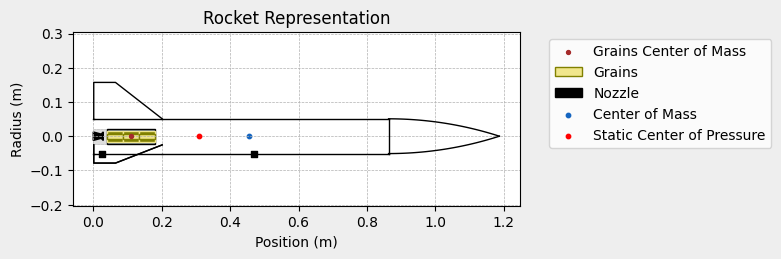

In [10]:
Phoenix.draw()


In [11]:
urrgFlight = Flight(
    rocket=Phoenix,
    environment=env_windy,
    max_time_step=0.001,
    rail_length=3.04800    ,
    inclination=86,          # Rail inclination angle (degrees from horizontal)
    heading=35,              # Launch direction (degrees from North)
)


Apogee State

Apogee Time: 10.248 s
Apogee Altitude: 1066.424 m (ASL) | 644.724 m (AGL)
Apogee Freestream Speed: 8.360 m/s
Apogee X position: 45.323 m
Apogee Y position: 72.873 m
Apogee latitude: 42.7051156°
Apogee longitude: -77.1911351°


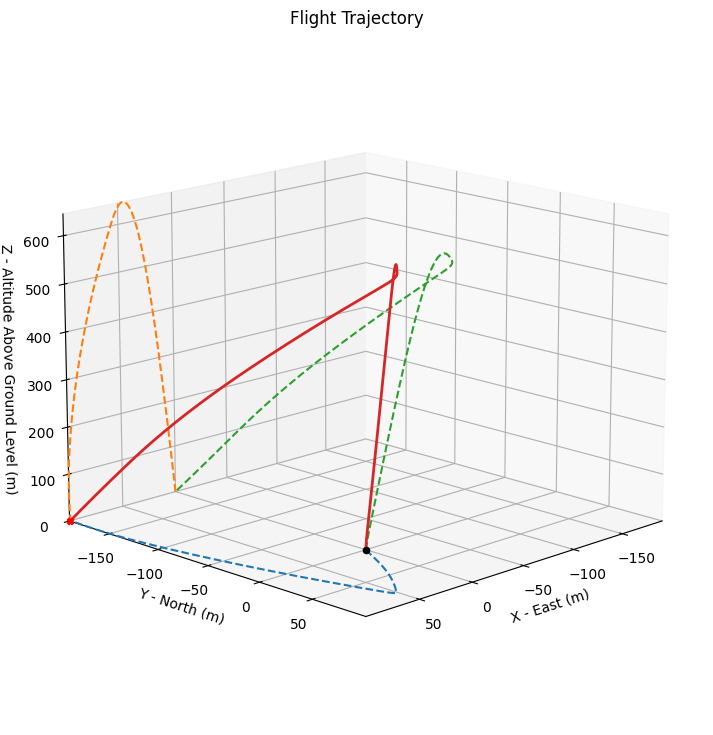

In [12]:
urrgFlight.prints.apogee_conditions()
urrgFlight.plots.trajectory_3d()


In [13]:
print(len(urrgFlight.solution))

94498


In [14]:
urrgFlight.prints.initial_conditions()
urrgFlight.prints.out_of_rail_conditions()


Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 421.70 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 0.953 | e1: -0.033 | e2: 0.010 | e3: -0.301
Euler Angles - Spin φ : 0.00° | Nutation θ: -4.00° | Precession ψ: -35.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00 rad/s
Initial Stability Margin: 1.449 c

Rail Departure State

Rail Departure Time: 0.130 s
Rail Departure Velocity: 41.886 m/s
Rail Departure Stability Margin: 1.536 c
Rail Departure Angle of Attack: 4.002°
Rail Departure Thrust-Weight Ratio: 36.249
Rail Departure Reynolds Number: 2.715e+05


In [17]:
from rocketpy.simulation.flight_data_exporter import FlightDataExporter

exporter = FlightDataExporter(urrgFlight)

exporter.export_kml(
    file_name="Paultrajectory.kml",
    extrude=True,
    altitude_mode="absolute"
)

File  Paultrajectory.kml  saved with success!
